# NIR-style: результаты прогноза mid-доходности GAZP

Визуализация `reports/stage-04-results.csv` и `stage-04-best.csv`: 5 сплитов, окна 7/10, горизонты 2/3, нормировки std/min-max, модели Ridge/RF/XGB.

Цель — mid-доходность GAZP `(open+close)/2`, накопленная за `h` дней после окна. yfinance-признаки сдвинуты на 1 торговый день; MC-винзоризация train; X val/test клипаются train-границами.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

res = pd.read_csv("reports/stage-04-results.csv")
best = pd.read_csv("reports/stage-04-best.csv")
print("results:", res.shape, "| best:", best.shape)
print("групп:", res.groupby(["norm", "window", "horizon", "model"]).ngroups)


results: (120, 30) | best: (24, 30)
групп: 24


In [2]:
g = best.loc[best["is_global_best"]].iloc[0]
cols = ["norm", "window", "horizon", "model", "params",
        "train_r2_mean", "val_r2_mean", "test_r2_mean",
        "val_ic_mean", "test_ic_mean", "val_sign_acc_mean", "test_sign_acc_mean"]
display(g[cols].to_frame().T.round(4))

idx = best.groupby("model")["val_mse_mean"].idxmin()
display(best.loc[idx, ["model", "norm", "window", "horizon", "params",
                       "val_r2_mean", "test_r2_mean", "val_ic_mean",
                       "test_ic_mean", "val_sign_acc_mean",
                       "test_sign_acc_mean"]].round(4))


,norm,window,horizon,model,params,train_r2_mean,val_r2_mean,test_r2_mean,val_ic_mean,test_ic_mean,val_sign_acc_mean,test_sign_acc_mean
0,minmax,7,2,rf,"{""max_depth"": 8, ""max_features"": 0.3, ""min_sam...",0.275486,0.02527,0.032247,0.174858,0.205327,0.555057,0.550594


,model,norm,window,horizon,params,val_r2_mean,test_r2_mean,val_ic_mean,test_ic_mean,val_sign_acc_mean,test_sign_acc_mean
0,rf,minmax,7,2,"{""max_depth"": 8, ""max_features"": 0.3, ""min_sam...",0.0253,0.0322,0.1749,0.2053,0.5551,0.5506
4,ridge,minmax,7,2,"{""alpha"": 316.22776601683796}",0.0076,0.0109,0.1189,0.1393,0.5180,0.5340
8,xgb,std,10,2,"{""learning_rate"": 0.05, ""max_depth"": 5, ""n_est...",0.0011,-0.0006,0.1706,0.1739,0.5471,0.5574


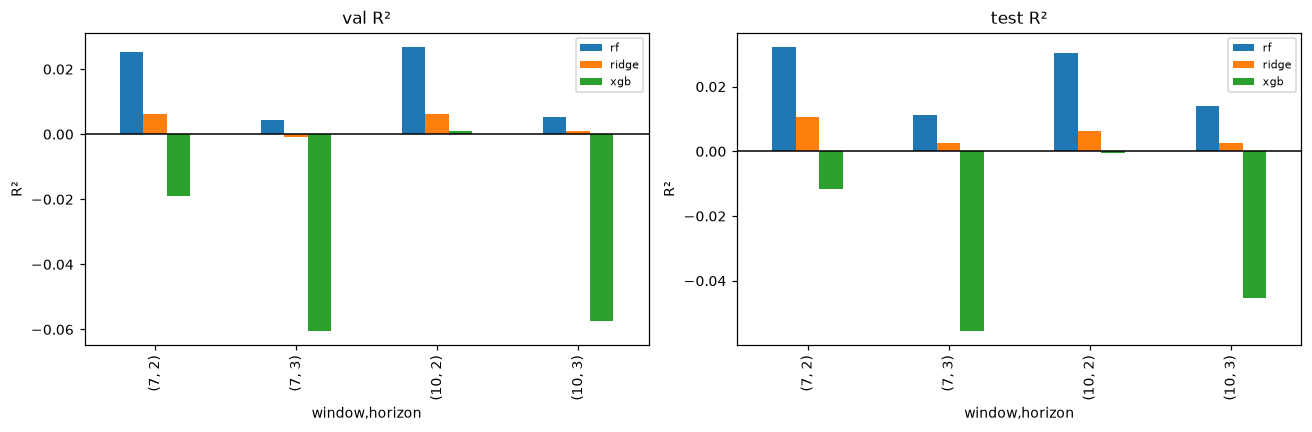

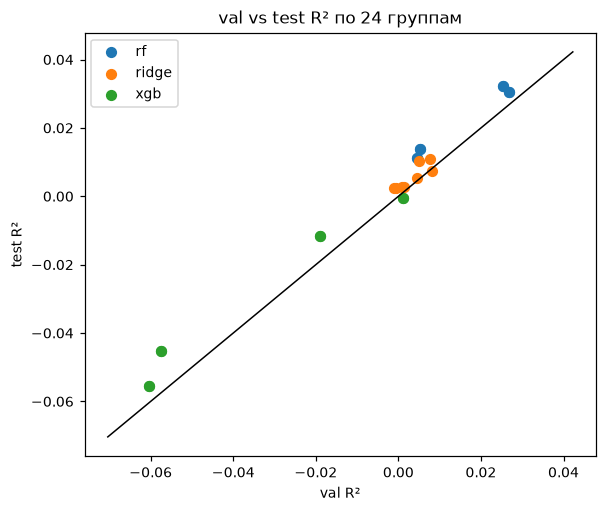

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in [(axes[0], "val_r2_mean", "val R²"),
                          (axes[1], "test_r2_mean", "test R²")]:
    pivot = best.pivot_table(index=["window", "horizon"], columns="model",
                             values=metric, aggfunc="mean")
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_ylabel("R²")
    ax.axhline(0, color="black", lw=1)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for model, part in best.groupby("model"):
    ax.scatter(part["val_r2_mean"], part["test_r2_mean"], label=model, s=40)
lim = [min(best["val_r2_mean"].min(), best["test_r2_mean"].min()) - 0.01,
       max(best["val_r2_mean"].max(), best["test_r2_mean"].max()) + 0.01]
ax.plot(lim, lim, color="black", lw=1)
ax.set_xlabel("val R²")
ax.set_ylabel("test R²")
ax.set_title("val vs test R² по 24 группам")
ax.legend()
plt.show()


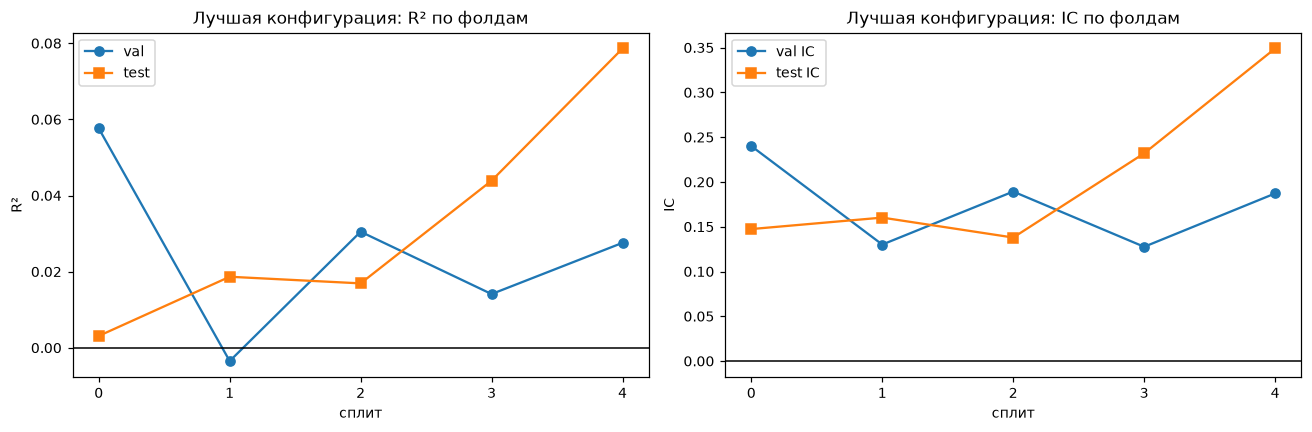

,split,train_r2,val_r2,test_r2,val_ic,test_ic,val_sign_acc,test_sign_acc
65,0,0.2745,0.0576,0.0031,0.2401,0.1474,0.6043,0.5202
66,1,0.2780,-0.0035,0.0187,0.1301,0.1602,0.5107,0.5273
67,2,0.2843,0.0305,0.0169,0.1893,0.1379,0.5724,0.5321
68,3,0.2882,0.0141,0.0439,0.1276,0.2320,0.5463,0.5487
69,4,0.2525,0.0276,0.0786,0.1872,0.3491,0.5416,0.6247


In [4]:
sel = res[(res.norm == g["norm"]) & (res.window == g["window"]) &
                (res.horizon == g["horizon"]) & (res.model == g["model"])]
sel = sel.sort_values("split")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(sel))
axes[0].plot(x, sel["val_r2"], marker="o", label="val")
axes[0].plot(x, sel["test_r2"], marker="s", label="test")
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xticks(x)
axes[0].set_xlabel("сплит")
axes[0].set_ylabel("R²")
axes[0].set_title("Лучшая конфигурация: R² по фолдам")
axes[0].legend()
axes[1].plot(x, sel["val_ic"], marker="o", label="val IC")
axes[1].plot(x, sel["test_ic"], marker="s", label="test IC")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xticks(x)
axes[1].set_xlabel("сплит")
axes[1].set_ylabel("IC")
axes[1].set_title("Лучшая конфигурация: IC по фолдам")
axes[1].legend()
plt.tight_layout()
plt.show()
display(sel[["split", "train_r2", "val_r2", "test_r2",
             "val_ic", "test_ic", "val_sign_acc", "test_sign_acc"]].round(4))


## Выводы

- Лучшая конфигурация по среднему val MSE — RF, окно 7, горизонт 2, `max_depth=8`, `min_samples_leaf=25`, `max_features=0.3`.
- RF даёт положительный R² на val и test, IC ≈ 0,17–0,21 и точность знака ≈ 55%; Ridge слабее, XGB переобучается (train R² ≈ 0,98, val/test — около нуля).
- Горизонт 2 дня устойчиво лучше горизонта 3; окна 7 и 10 близки.
- std и min-max для RF дают **точное равенство** val MSE (деревья инвариантны к монотонному масштабированию); глобальный best обходит std-двойника на 3·10⁻⁹ — это ничья, а не эффект нормировки.
- Визуализация подтверждает: разброс по фолдам большой, лучший фолд — не гарантия лучшего теста; смотреть на средние и на устойчивость.
- Fold4 (строгий walk-forward) не хуже fold0–3 (test R² 0,079 против 0,021), поэтому завышения из-за train с будущими кусками не видно; но сигнал слабый: 43 из 120 строк с test R² < 0.

Ограничения: train включает будущие куски; y val/test сырые (экстремумы 2020/2022); 156 строк с нулевыми yf-доходностями; сравнение с NIR некорректно из-за shift(1).
